# RQ1 Run-8 19:12 final physical-to-virtual synchronisation evaluation

This executed notebook evaluates `EXP_RQ1_ALL_NODE_POWER_CYCLE_20261006_191233`, the completed six-node physical power-cycle campaign selected as the primary RQ1 confirmatory candidate. It creates a frozen evidence snapshot, analysis-ready datasets, validation checks, and publication-ready figures.

The evaluated system used IndoorTwin RQ1 Backend v1.2, registry `room01-entity-registry-v1.3`, and freshness configuration `freshness-v1`. Door, window, fan, vibration, and differential-pressure channels are FAST (10 s); indoor/outdoor environmental channels, occupancy, heater current, and heater state are MEDIUM (30 s).

After reconnection, stale properties returned to `FRESH` only when the backend received and accepted new valid MQTT telemetry messages for those properties. Status, diagnostics, malformed, duplicate, out-of-order, and rejected observations do not refresh a property.

The timestamps are host-observed freshness and recovery times. Operator confirmation is not the exact electrical switching instant. The results therefore do not establish network latency or end-to-end sensor-to-screen latency. The earlier 18:05 campaign is pilot threshold-calibration evidence and is not pooled with this registry-v1.3 confirmatory campaign.

Saved results and plots are included below; no rerun is needed to inspect them. Regeneration is optional.

Scope: six physical node power interruptions. All inputs are frozen repository files; no live hardware or external experiment directory is read.

## 1. Reproducibility setup and evidence freeze

The next cell locates the packaged completed campaign, verifies the required inputs, and copies the eight analysis-relevant evidence files plus the evaluated registry and freshness configuration into this package. The two large raw audit streams remain in the original campaign; their paths, sizes, and SHA-256 checksums are recorded without duplication.

The notebook can be rerun from the live workspace or, for the included analyses, from the packaged evidence snapshot.

In [1]:
from pathlib import Path
import hashlib, json, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', category=RuntimeWarning)
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 180)

from pathlib import Path
import sys

REPO_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                  if (p / "notebooks").is_dir() and (p / "src" / "indoortwin" / "paths.py").is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the repository.")
sys.path.insert(0, str(REPO_ROOT / "src"))
PACKAGE_ROOT = REPO_ROOT
NOTEBOOK_DIR = REPO_ROOT / "notebooks"
SOURCE_SNAPSHOT = REPO_ROOT / "data/rq1_power/EXP_RQ1_ALL_NODE_POWER_CYCLE_20261006_191233"
CONFIG_SNAPSHOT = REPO_ROOT / "data/rq1_power/config"
TABLE_DIR = REPO_ROOT / "results/rq1_power/tables"
FIGURE_DIR = REPO_ROOT / "results/rq1_power/figures"
for directory in (TABLE_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
EVIDENCE_FILES = [
    'experiment_manifest.json', 'received_values.csv', 'state_transitions.csv',
    'power_cycle_scope.json', 'rq1_node_summary.csv',
    'rq1_dropout_recovery_summary.csv', 'rq1_property_summary.csv',
    'rq1_healthy_window_summary.csv'
]
def sha256(path):
    h = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

SOURCE = SOURCE_SNAPSHOT
assert all((SOURCE / name).exists() for name in EVIDENCE_FILES), 'Packaged evidence snapshot is incomplete.'

with (SOURCE / 'experiment_manifest.json').open(encoding='utf-8') as f:
    manifest = json.load(f)
with (SOURCE / 'power_cycle_scope.json').open(encoding='utf-8') as f:
    power_scope = json.load(f)
with (CONFIG_SNAPSHOT / 'room01_entity_registry_v1.3.json').open(encoding='utf-8') as f:
    registry = json.load(f)
with (CONFIG_SNAPSHOT / 'freshness_v1.json').open(encoding='utf-8') as f:
    freshness_config = json.load(f)

received = pd.read_csv(SOURCE / 'received_values.csv')
transitions = pd.read_csv(SOURCE / 'state_transitions.csv')
node_summary = pd.read_csv(SOURCE / 'rq1_node_summary.csv')
dropout = pd.read_csv(SOURCE / 'rq1_dropout_recovery_summary.csv')
property_summary = pd.read_csv(SOURCE / 'rq1_property_summary.csv')
healthy = pd.read_csv(SOURCE / 'rq1_healthy_window_summary.csv')

for frame in (received, transitions):
    for col in frame.columns:
        if col.endswith('_utc') or col.endswith('_time') or col in {'received_at', 'timestamp'}:
            frame[col] = pd.to_datetime(frame[col], utc=True, errors='coerce')

print('Campaign:', manifest.get('experiment_id'))
print('Status:', manifest.get('run_status'))
print('Evidence files:', len(EVIDENCE_FILES))
print('Received observations:', len(received))
print('Freshness transitions:', len(transitions))


Campaign: EXP_RQ1_ALL_NODE_POWER_CYCLE_20261006_191233
Status: COMPLETE
Evidence files: 8
Received observations: 6773
Freshness transitions: 54


## 2. Integrity, completion, and configuration validation

These checks prevent an incomplete or differently configured campaign from being interpreted as the final RQ1 evaluation. A passing result requires a completed manifest, all six planned nodes, all physical cycle checks, new restart sessions, valid sequence handling, 27 matched property recoveries, the expected 18 FAST and 9 MEDIUM properties, and exact agreement between each observed property threshold and registry v1.3.

The healthy-window values are one-second polling checks of backend state, not independent sensor samples.

In [2]:
def all_true(series):
    return bool(pd.Series(series).astype(str).str.lower().eq('true').all())

# Pair every FRESH→STALE transition with its STALE→FRESH recovery.
stale = transitions[(transitions.old_quality == 'FRESH') & (transitions.new_quality == 'STALE')].copy()
fresh = transitions[(transitions.old_quality == 'STALE') & (transitions.new_quality == 'FRESH')].copy()
stale['node_id'] = stale['source_message_id'].str.split('/').str[0]
fresh['node_id'] = fresh['source_message_id'].str.split('/').str[0]
stale = stale.rename(columns={'transition_time':'stale_time','freshness_age_s':'stale_age_s','threshold_s':'configured_threshold_s','reason':'stale_reason','source_message_id':'stale_source_message_id'})
fresh = fresh.rename(columns={'transition_time':'fresh_time','reason':'recovery_reason','source_message_id':'fresh_source_message_id'})
property_metrics = stale[['experiment_id','node_id','entity_id','property','stale_time','stale_age_s','configured_threshold_s','stale_reason','stale_source_message_id','config_version']].merge(
    fresh[['node_id','entity_id','property','fresh_time','recovery_reason','fresh_source_message_id']],
    on=['node_id','entity_id','property'], how='left', validate='one_to_one')
property_metrics['freshness_class'] = np.where(property_metrics.configured_threshold_s.eq(10), 'FAST', 'MEDIUM')
property_metrics['threshold_overshoot_s'] = property_metrics.stale_age_s - property_metrics.configured_threshold_s
property_metrics['stale_duration_s'] = (property_metrics.fresh_time - property_metrics.stale_time).dt.total_seconds()
property_metrics['valid_recovery'] = property_metrics.recovery_reason.eq('NEW_VALID_READING') & property_metrics.fresh_time.notna()

registry_frame = pd.DataFrame(registry['properties'])
registry_eval = property_metrics.merge(
    registry_frame[['node_id','entity_id','property','freshness_class']].rename(columns={'freshness_class':'registry_freshness_class'}),
    on=['node_id','entity_id','property'], how='left', validate='one_to_one')
registry_eval['registry_threshold_s'] = registry_eval.registry_freshness_class.map({k:v['stale_after_s'] for k,v in freshness_config['classes'].items()})
registry_alignment = bool((registry_eval.freshness_class == registry_eval.registry_freshness_class).all() and
                          np.isclose(registry_eval.configured_threshold_s, registry_eval.registry_threshold_s).all())

expected_nodes = set(power_scope['power_cycle_nodes'])
checks = [
    ('manifest_complete', manifest.get('run_status') == 'COMPLETE' and manifest.get('stop_reason') == 'COMPLETE', manifest.get('run_status')),
    ('registry_version_v1_3', manifest.get('registry_version') == registry.get('registry_version') == 'room01-entity-registry-v1.3', manifest.get('registry_version')),
    ('freshness_config_v1', freshness_config.get('version') == 'freshness-v1' and transitions.config_version.eq('freshness-v1').all(), freshness_config.get('version')),
    ('six_planned_nodes', set(node_summary.node_id) == expected_nodes and len(node_summary) == 6, len(node_summary)),
    ('healthy_window_all_nodes', all_true(healthy['pass']) and healthy.samples_checked.eq(30).all(), f"{all_true(healthy['pass'])}; 30 checks/node"),
    ('physical_cycles_all_pass', all_true(node_summary.overall_pass) and all_true(dropout['pass']), int(pd.Series(dropout['pass']).astype(str).str.lower().eq('true').sum())),
    ('new_session_after_restart', all_true(dropout.session_changed_after_reboot) and all_true(node_summary.session_recovery_new_id), int(pd.Series(dropout.session_changed_after_reboot).astype(str).str.lower().eq('true').sum())),
    ('sequence_handling_all_pass', all_true(node_summary.sequence_ok), int(pd.Series(node_summary.sequence_ok).astype(str).str.lower().eq('true').sum())),
    ('interruption_isolation_all_pass', all_true(dropout.other_nodes_fresh), int(pd.Series(dropout.other_nodes_fresh).astype(str).str.lower().eq('true').sum())),
    ('27_stale_transitions', len(stale) == 27, len(stale)),
    ('27_matched_valid_recoveries', len(property_metrics) == 27 and property_metrics.valid_recovery.all(), int(property_metrics.valid_recovery.sum())),
    ('threshold_class_counts', property_metrics.freshness_class.value_counts().to_dict() == {'FAST':18,'MEDIUM':9}, property_metrics.freshness_class.value_counts().to_dict()),
    ('registry_threshold_alignment', registry_alignment, registry_alignment),
    ('overshoot_under_one_second', property_metrics.threshold_overshoot_s.between(0,1, inclusive='both').all(), property_metrics.threshold_overshoot_s.max()),
]
validation_checks = pd.DataFrame(checks, columns=['check','pass','observed'])
assert validation_checks['pass'].all(), validation_checks.loc[~validation_checks['pass']].to_dict('records')

validation_checks.to_csv(TABLE_DIR / 'validation_checks.csv', index=False)
healthy.to_csv(TABLE_DIR / 'healthy_window_evaluation.csv', index=False)
node_summary.to_csv(TABLE_DIR / 'node_outcomes.csv', index=False)
property_metrics.to_csv(TABLE_DIR / 'property_transition_metrics.csv', index=False)
registry_eval.to_csv(TABLE_DIR / 'registry_threshold_alignment.csv', index=False)

display(validation_checks)
display(property_metrics.head(8).round(3))


,check,pass,observed
0,manifest_complete,True,COMPLETE
1,registry_version_v1_3,True,room01-entity-registry-v1.3
2,freshness_config_v1,True,freshness-v1
3,six_planned_nodes,True,6
4,healthy_window_all_nodes,True,True; 30 checks/node
5,physical_cycles_all_pass,True,6
6,new_session_after_restart,True,6
7,sequence_handling_all_pass,True,6
8,interruption_isolation_all_pass,True,6
9,27_stale_transitions,True,27


C:\Users\AMN\AppData\Local\Temp\ipykernel_53756\3465663380.py:54: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(property_metrics.head(8).round(3))


,experiment_id,node_id,entity_id,property,stale_time,stale_age_s,configured_threshold_s,stale_reason,stale_source_message_id,config_version,fresh_time,recovery_reason,fresh_source_message_id,freshness_class,threshold_overshoot_s,stale_duration_s,valid_recovery
0,EXP_RQ1_ALL_NODE_POWER_CYCLE_20261006_191233,ENV-IN-01,ROOM01,co2_indoor,2026-10-06 06:13:41.434088+00:00,30.639,30.0,NO_NEW_DATA,ENV-IN-01/ENV-IN-01_7427EB16A398_8C27BFA1/1876...,freshness-v1,2026-10-06 06:13:57.316114+00:00,NEW_VALID_READING,ENV-IN-01/ENV-IN-01_7427EB16A398_3B95C000/1/RO...,MEDIUM,0.639,15.882,True
1,EXP_RQ1_ALL_NODE_POWER_CYCLE_20261006_191233,ENV-IN-01,ROOM01,temperature_indoor,2026-10-06 06:13:41.434088+00:00,30.639,30.0,NO_NEW_DATA,ENV-IN-01/ENV-IN-01_7427EB16A398_8C27BFA1/1876...,freshness-v1,2026-10-06 06:13:57.318025+00:00,NEW_VALID_READING,ENV-IN-01/ENV-IN-01_7427EB16A398_3B95C000/1/RO...,MEDIUM,0.639,15.884,True
2,EXP_RQ1_ALL_NODE_POWER_CYCLE_20261006_191233,ENV-IN-01,ROOM01,rh_indoor,2026-10-06 06:13:41.434088+00:00,30.638,30.0,NO_NEW_DATA,ENV-IN-01/ENV-IN-01_7427EB16A398_8C27BFA1/1876...,freshness-v1,2026-10-06 06:13:57.319023+00:00,NEW_VALID_READING,ENV-IN-01/ENV-IN-01_7427EB16A398_3B95C000/1/RO...,MEDIUM,0.638,15.885,True
3,EXP_RQ1_ALL_NODE_POWER_CYCLE_20261006_191233,ENV-OUT-01,OUTDOOR-REF,co2,2026-10-06 06:14:35.471983+00:00,30.633,30.0,NO_NEW_DATA,ENV-OUT-01/ENV-OUT-01_D060D48FCBA4_7DF86CF4/18...,freshness-v1,2026-10-06 06:14:48.760682+00:00,NEW_VALID_READING,ENV-OUT-01/ENV-OUT-01_D060D48FCBA4_BBEB13C6/1/...,MEDIUM,0.633,13.289,True
4,EXP_RQ1_ALL_NODE_POWER_CYCLE_20261006_191233,ENV-OUT-01,OUTDOOR-REF,temperature,2026-10-06 06:14:35.471983+00:00,30.632,30.0,NO_NEW_DATA,ENV-OUT-01/ENV-OUT-01_D060D48FCBA4_7DF86CF4/18...,freshness-v1,2026-10-06 06:14:48.761678+00:00,NEW_VALID_READING,ENV-OUT-01/ENV-OUT-01_D060D48FCBA4_BBEB13C6/1/...,MEDIUM,0.632,13.290,True
5,EXP_RQ1_ALL_NODE_POWER_CYCLE_20261006_191233,ENV-OUT-01,OUTDOOR-REF,rh,2026-10-06 06:14:35.471983+00:00,30.631,30.0,NO_NEW_DATA,ENV-OUT-01/ENV-OUT-01_D060D48FCBA4_7DF86CF4/18...,freshness-v1,2026-10-06 06:14:48.762677+00:00,NEW_VALID_READING,ENV-OUT-01/ENV-OUT-01_D060D48FCBA4_BBEB13C6/1/...,MEDIUM,0.631,13.291,True
6,EXP_RQ1_ALL_NODE_POWER_CYCLE_20261006_191233,OCC-IN-01,ROOM01,occupancy,2026-10-06 06:15:25.502583+00:00,30.341,30.0,NO_NEW_DATA,OCC-IN-01/OCC-IN-01_28DB48858428_38B096F6/1453...,freshness-v1,2026-10-06 06:15:35.779207+00:00,NEW_VALID_READING,OCC-IN-01/OCC-IN-01_28DB48858428_D166E974/1/RO...,MEDIUM,0.341,10.277,True
7,EXP_RQ1_ALL_NODE_POWER_CYCLE_20261006_191233,HEAT-MON-01,HEATER-01,current,2026-10-06 06:16:14.534620+00:00,30.542,30.0,NO_NEW_DATA,HEAT-MON-01/HEAT-MON-01_DCCE3B09AF70_EF38EC4E/...,freshness-v1,2026-10-06 06:16:23.559972+00:00,NEW_VALID_READING,HEAT-MON-01/HEAT-MON-01_DCCE3B09AF70_1C9FD368/...,MEDIUM,0.542,9.025,True


## Freshness and measurement plots

The freshness timeline shows the number of properties remaining FRESH for each interrupted node. Measurement plots retain telemetry gaps during the same interruptions. The selected evidence plots are displayed at the end of this notebook. Intermediate timing plots use this same campaign.

## Recorded measurements

The accepted-measurement CSV contains environmental readings, occupancy, opening states, heater state/current, fan command/RPM/current, vibration and differential pressure. Interruption bands use confirmed disconnection and host-observed restoration times. Missing telemetry remains a gap.

## 3. Evaluation metrics and operational definitions

For property \(p\), the backend declares staleness when the host-observed age exceeds its configured threshold \(T_p\). The recorded overshoot is:

\[
O_p = A_p(t_{stale}) - T_p
\]

where \(A_p(t_{stale})\) is the recorded property age at the `FRESH→STALE` transition. A small positive overshoot is expected because expiry is detected by a periodic backend check rather than continuously.

Two node-level timing views are retained:

1. **Exact transition timing:** derived from property transitions; disconnect confirmation to the last target-property stale transition, and reconnect confirmation to the last target-property fresh transition.
2. **Polling-completion timing:** derived from the automation summary; confirmation to the next polling check that observed all target properties in the required state.

Neither view is exact hardware-switch latency. The comparison quantifies backend observation and harness polling granularity.

In [3]:
for col in ['disconnect_confirmed_time','stale_detected_time','reconnect_confirmed_time','node_properties_fresh_time']:
    dropout[col] = pd.to_datetime(dropout[col], utc=True, errors='raise')

exact_by_node = property_metrics.groupby('node_id', as_index=False).agg(
    first_stale_transition_time=('stale_time','min'),
    all_properties_stale_time=('stale_time','max'),
    first_fresh_transition_time=('fresh_time','min'),
    all_properties_fresh_transition_time=('fresh_time','max'),
    target_property_count=('property','size'),
    max_threshold_overshoot_s=('threshold_overshoot_s','max'),
    mean_threshold_overshoot_s=('threshold_overshoot_s','mean'))
node_metrics = dropout.merge(exact_by_node, on='node_id', validate='one_to_one')
node_metrics['confirm_to_all_stale_exact_s'] = (node_metrics.all_properties_stale_time - node_metrics.disconnect_confirmed_time).dt.total_seconds()
node_metrics['confirm_to_all_fresh_exact_s'] = (node_metrics.all_properties_fresh_transition_time - node_metrics.reconnect_confirmed_time).dt.total_seconds()
node_metrics['confirm_to_all_stale_polling_s'] = (node_metrics.stale_detected_time - node_metrics.disconnect_confirmed_time).dt.total_seconds()
node_metrics['confirm_to_all_fresh_polling_s'] = (node_metrics.node_properties_fresh_time - node_metrics.reconnect_confirmed_time).dt.total_seconds()
node_metrics['fresh_polling_minus_exact_s'] = node_metrics.confirm_to_all_fresh_polling_s - node_metrics.confirm_to_all_fresh_exact_s

threshold_summary = property_metrics.groupby(['freshness_class','configured_threshold_s'], as_index=False).agg(
    properties=('property','size'),
    stale_age_min_s=('stale_age_s','min'),
    stale_age_mean_s=('stale_age_s','mean'),
    stale_age_max_s=('stale_age_s','max'),
    overshoot_min_s=('threshold_overshoot_s','min'),
    overshoot_mean_s=('threshold_overshoot_s','mean'),
    overshoot_max_s=('threshold_overshoot_s','max'),
    all_valid_recovery=('valid_recovery','all'))

# Observation quality is evaluated at both property-row and telemetry-bundle level.
received['received_time'] = pd.to_datetime(received['received_time'], utc=True, errors='raise')
bundles = (received.groupby(['node_id','session_id','sequence'], as_index=False)
           .agg(received_time=('received_time','min'), property_rows=('property','size'),
                all_valid=('validation_status', lambda s: s.eq('VALID').all()),
                all_state_updated=('state_updated', lambda s: pd.Series(s).astype(str).str.lower().eq('true').all())))
bundles = bundles.sort_values(['node_id','session_id','sequence'])
bundles['interarrival_s'] = bundles.groupby(['node_id','session_id']).received_time.diff().dt.total_seconds()
bundles['sequence_increment'] = bundles.groupby(['node_id','session_id']).sequence.diff()
bundles['sequence_non_increasing'] = bundles.sequence_increment.le(0).fillna(False)

mqtt_quality = pd.DataFrame([
    ('property_rows', len(received)),
    ('valid_property_rows', int(received.validation_status.eq('VALID').sum())),
    ('state_updated_property_rows', int(received.state_updated.astype(str).str.lower().eq('true').sum())),
    ('telemetry_bundles', len(bundles)),
    ('all_valid_bundles', int(bundles.all_valid.sum())),
    ('non_increasing_sequence_bundles', int(bundles.sequence_non_increasing.sum())),
], columns=['measure','count'])
interarrival_summary = (bundles.dropna(subset=['interarrival_s']).groupby('node_id', as_index=False)
                        .agg(interval_count=('interarrival_s','size'), median_interarrival_s=('interarrival_s','median'),
                             p95_interarrival_s=('interarrival_s', lambda s: s.quantile(.95)),
                             max_interarrival_s=('interarrival_s','max')))

node_metrics.to_csv(TABLE_DIR / 'node_cycle_metrics.csv', index=False)
threshold_summary.to_csv(TABLE_DIR / 'threshold_class_summary.csv', index=False)
mqtt_quality.to_csv(TABLE_DIR / 'mqtt_observation_quality.csv', index=False)
interarrival_summary.to_csv(TABLE_DIR / 'mqtt_interarrival_summary.csv', index=False)
bundles.to_csv(TABLE_DIR / 'mqtt_bundle_observations.csv', index=False)

display(node_metrics[['node_id','target_property_count','confirm_to_all_stale_exact_s','confirm_to_all_fresh_exact_s','confirm_to_all_fresh_polling_s']].round(3))
display(threshold_summary.round(3))
display(mqtt_quality)

,node_id,target_property_count,confirm_to_all_stale_exact_s,confirm_to_all_fresh_exact_s,confirm_to_all_fresh_polling_s
0,ENV-IN-01,3,29.636,6.226,7.005
1,ENV-OUT-01,3,27.914,6.332,7.005
2,OCC-IN-01,1,28.215,2.006,3.002
3,HEAT-MON-01,2,28.506,3.259,4.003
4,VIB-FAN-01,6,8.386,3.543,4.012
5,VENT-CTRL-01,12,8.899,12.499,13.010


,freshness_class,configured_threshold_s,properties,stale_age_min_s,stale_age_mean_s,stale_age_max_s,overshoot_min_s,overshoot_mean_s,overshoot_max_s,all_valid_recovery
0,FAST,10.0,18,10.415,10.557,10.632,0.415,0.557,0.632,True
1,MEDIUM,30.0,9,30.341,30.582,30.639,0.341,0.582,0.639,True


,measure,count
0,property_rows,6773
1,valid_property_rows,6773
2,state_updated_property_rows,6773
3,telemetry_bundles,1958
4,all_valid_bundles,1958
5,non_increasing_sequence_bundles,0


## 4. Publication-ready figures

Figures are generated in both PNG (300 dpi) and SVG. Colour encodes configured threshold class consistently: FAST is blue and MEDIUM is orange. Interruption bands begin at operator disconnect confirmation and end at the last accepted valid property recovery for the interrupted node.

In [4]:
COLORS = {'FAST':'#2468A2', 'MEDIUM':'#E68613'}
NODE_COLORS = dict(zip(manifest['power_cycle_order'], plt.cm.tab10.colors[:6]))

def save_figure(fig, stem):
    fig.savefig(FIGURE_DIR / f'{stem}.png', dpi=300, bbox_inches='tight', facecolor='white')
    fig.savefig(FIGURE_DIR / f'{stem}.svg', bbox_inches='tight', facecolor='white')
    plt.close(fig)

plot_pm = property_metrics.sort_values(['node_id','entity_id','property']).copy()
plot_pm['label'] = plot_pm.node_id + ' | ' + plot_pm.entity_id + '/' + plot_pm.property
origin = plot_pm.stale_time.min()
plot_pm['stale_start_s'] = (plot_pm.stale_time - origin).dt.total_seconds()
plot_pm['fresh_end_s'] = (plot_pm.fresh_time - origin).dt.total_seconds()

# Property-level stale intervals.
fig, ax = plt.subplots(figsize=(12, 10))
y = np.arange(len(plot_pm))
for yi, row in enumerate(plot_pm.itertuples()):
    ax.barh(yi, row.fresh_end_s-row.stale_start_s, left=row.stale_start_s,
            color=COLORS[row.freshness_class], alpha=.85, height=.72)
ax.set_yticks(y, plot_pm.label, fontsize=7)
ax.invert_yaxis(); ax.set_xlabel('Seconds after first FRESH→STALE transition')
ax.set_title('Registered-property stale intervals and recovery after valid telemetry')
ax.legend(handles=[plt.Rectangle((0,0),1,1,color=COLORS[k],label=f'{k} ({10 if k=="FAST" else 30} s)') for k in COLORS], loc='lower right')
save_figure(fig, 'rq1_191233_figure_fresh_stale_fresh')

# Age at staleness.
fig, ax = plt.subplots(figsize=(12, 9))
for cls in ['FAST','MEDIUM']:
    part = plot_pm[plot_pm.freshness_class.eq(cls)]
    pos = [plot_pm.index.get_loc(i) for i in part.index]
    ax.barh(pos, part.stale_age_s, color=COLORS[cls], alpha=.85, label=cls)
    ax.scatter(part.configured_threshold_s, pos, marker='|', s=140, color='black', zorder=3)
ax.set_yticks(y, plot_pm.label, fontsize=7); ax.invert_yaxis()
ax.set_xlabel('Property age at FRESH→STALE transition (s)')
ax.set_title('Observed property age and configured threshold at stale transition')
ax.legend(title='Threshold class')
save_figure(fig, 'rq1_191233_figure_stale_transition_timing')

# Node-level confirmation timing.
order = manifest['power_cycle_order']
nm = node_metrics.set_index('node_id').loc[order].reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
axes[0].barh(nm.node_id, nm.confirm_to_all_stale_exact_s, color='#B94E48')
axes[1].barh(nm.node_id, nm.confirm_to_all_fresh_exact_s, color='#3D8B6D')
for ax, values, title in [(axes[0],nm.confirm_to_all_stale_exact_s,'Disconnect confirmation → all STALE'),
                          (axes[1],nm.confirm_to_all_fresh_exact_s,'Reconnect confirmation → all FRESH')]:
    for i, v in enumerate(values): ax.text(v+.25, i, f'{v:.2f} s', va='center', fontsize=8)
    ax.set_xlabel('Host-observed seconds'); ax.set_title(title)
fig.suptitle('Exact property-transition timing by interrupted node', y=1.02)
save_figure(fig, 'rq1_191233_dropout_recovery_timing')

# FRESH property count from confirmed disconnection through recovery.
from matplotlib.lines import Line2D

line_colour = '#1F77B4'
fig, axes = plt.subplots(3, 2, figsize=(10, 8.1), sharex=False)
for ax, node in zip(axes.flat, order):
    nprop = property_metrics[property_metrics.node_id.eq(node)].sort_values(['stale_time','entity_id','property'])
    drow = node_metrics[node_metrics.node_id.eq(node)].iloc[0]
    property_count = len(nprop)
    limits = nprop.configured_threshold_s.dropna().unique()
    assert len(limits) == 1, f'Mixed freshness limits for {node}: {limits}'
    limit_s = int(limits[0])
    reconnect_s = (drow.reconnect_confirmed_time-drow.disconnect_confirmed_time).total_seconds()

    # The verified pre-interruption state supplies the count at t=0.
    events = [(0.0, property_count)]
    count = property_count
    for row in nprop.sort_values(['stale_time','entity_id','property']).itertuples():
        count -= 1
        elapsed = (row.stale_time-drow.disconnect_confirmed_time).total_seconds()
        events.append((elapsed, count))
    for row in nprop.sort_values(['fresh_time','entity_id','property']).itertuples():
        count += 1
        elapsed = (row.fresh_time-drow.disconnect_confirmed_time).total_seconds()
        events.append((elapsed, count))
    events.sort(key=lambda item: item[0])
    end_s = max(events[-1][0], reconnect_s) + 3.0
    events.append((end_s, count))
    x = [event[0] for event in events]
    values = [event[1] for event in events]

    ax.step(x, values, where='post', color=line_colour, linewidth=2.2, zorder=3)
    ax.scatter(x[1:-1], values[1:-1], color=line_colour, s=22, zorder=4)
    ax.axvline(0, color='black', linestyle=(0, (1, 2)), linewidth=1.8, zorder=2)
    ax.axvline(reconnect_s, color='black', linestyle=(0, (5, 2)), linewidth=1.8, zorder=2)
    ax.set_xlim(-1.0, end_s)
    ax.set_ylim(-0.15, property_count + 0.55)
    y_step = 1 if property_count <= 6 else 2
    ax.set_yticks(np.arange(0, property_count + 1, y_step))
    ax.set_title(f'{node}  ·  {property_count} properties, {limit_s} s limit', fontsize=13.5)
    ax.set_ylabel('FRESH properties', fontsize=12)
    ax.set_xlabel('Time since confirmed disconnection (s)', fontsize=12)
    ax.tick_params(axis='both', labelsize=11)
    ax.grid(True, alpha=.28, linewidth=.8)

legend_handles = [
    Line2D([0],[0], color=line_colour, linewidth=2.2, label='FRESH property count'),
    Line2D([0],[0], color='black', linestyle=(0,(1,2)), linewidth=1.8, label='Disconnection confirmed'),
    Line2D([0],[0], color='black', linestyle=(0,(5,2)), linewidth=1.8, label='Reconnection confirmed'),
]
fig.suptitle('Property freshness during physical power interruptions', fontsize=17, y=.988)
fig.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(.5, .95), ncol=3, frameon=False, fontsize=12.5)
fig.tight_layout(rect=(0, .025, 1, .88), h_pad=1.25, w_pad=1.0)
save_figure(fig, 'rq1_191233_fresh_property_count_timeline')

# Threshold conformance and overshoot.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for cls, part in property_metrics.groupby('freshness_class'):
    axes[0].scatter(part.configured_threshold_s, part.stale_age_s, color=COLORS[cls], s=45, alpha=.8, label=cls)
    axes[1].scatter(np.repeat(cls, len(part)), part.threshold_overshoot_s, color=COLORS[cls], s=45, alpha=.8)
axes[0].plot([9,31],[9,31], '--', color='black', linewidth=1); axes[0].set_xlim(8,32); axes[0].set_ylim(8,32)
axes[0].set_xlabel('Configured threshold (s)'); axes[0].set_ylabel('Observed stale age (s)'); axes[0].legend()
axes[1].axhline(0, color='black', linewidth=1); axes[1].set_xlabel('Threshold class'); axes[1].set_ylabel('Overshoot (s)')
fig.suptitle('Freshness-threshold conformance')
save_figure(fig, 'rq1_191233_threshold_conformance')

print('Generated core figures:', len(list(FIGURE_DIR.glob('rq1_191233*'))))

Generated core figures: 10


In [5]:
def numeric_signal(entity, prop):
    s = received[(received.entity_id == entity) & (received.property == prop)].copy().sort_values('received_time')
    s['numeric_value'] = pd.to_numeric(s.value, errors='coerce')
    state_map = {'UNOCCUPIED':0, 'OCCUPIED':1, 'FALSE':0, 'TRUE':1, 'CLOSED':0, 'OPEN':1, 'OFF':0, 'ON':1, 'ABSENT':0, 'PRESENT':1, 'HEATER_OFF':0, 'HEATER_LEVEL1':1, 'HEATER_LEVEL2':2, 'HEATER_LEVEL3':3}
    s['numeric_value'] = s.numeric_value.fillna(s.value.astype(str).str.upper().map(state_map))
    return s.dropna(subset=['numeric_value'])

def plot_broken(ax, frame, label, **kwargs):
    if frame.empty: return
    groups = frame.received_time.diff().dt.total_seconds().gt(15).cumsum()
    for j, (_, segment) in enumerate(frame.groupby(groups)):
        ax.plot(segment.received_time, segment.numeric_value, label=label if j == 0 else None, **kwargs)

panels = [
    [('ROOM01','co2_indoor','Indoor CO$_2$'),('OUTDOOR-REF','co2','Outdoor CO$_2$')],
    [('ROOM01','temperature_indoor','Indoor temperature'),('OUTDOOR-REF','temperature','Outdoor temperature')],
    [('ROOM01','rh_indoor','Indoor RH'),('OUTDOOR-REF','rh','Outdoor RH')],
    [('HEATER-01','current','Heater current')],
    [('FAN-EXH','rpm','Exhaust RPM'),('FAN-IN-01','rpm','Intake 1 RPM'),('FAN-IN-02','rpm','Intake 2 RPM')],
    [('ROOM01','occupancy','Occupancy'),('DOOR-01','state','Door'),('WINDOW-01','state','Window'),('HEATER-01','state','Heater state')]
]
ylabels = ['CO$_2$\n(ppm)','Temperature\n(°C)','Relative humidity\n(%)','Current\n(A)','Speed\n(rpm)','Encoded\nstate']
from matplotlib.patches import Patch
from zoneinfo import ZoneInfo

fig, axes = plt.subplots(6, 1, figsize=(10, 10), sharex=True)
for ax, specs, ylabel in zip(axes, panels, ylabels):
    for entity, prop, label in specs:
        plot_broken(ax, numeric_signal(entity, prop), label, linewidth=1.7)
    for row in nm.itertuples():
        ax.axvspan(row.disconnect_confirmed_time, row.all_properties_fresh_transition_time,
                   color=NODE_COLORS[row.node_id], alpha=.12)
    ax.set_ylabel(ylabel, fontsize=13.5, labelpad=8)
    ax.tick_params(axis='both', labelsize=12.5)
    ax.legend(loc='upper right', fontsize=12, ncol=min(4, len(specs)), framealpha=.92)
    ax.grid(True, alpha=.25, linewidth=.8)
local_tz = ZoneInfo('Pacific/Auckland')
axes[-1].set_xlabel('Local time on 6 October 2026 (Pacific/Auckland)', fontsize=14)
axes[-1].xaxis.set_major_formatter(DateFormatter('%H:%M:%S', tz=local_tz))
node_order = nm.sort_values('disconnect_confirmed_time').node_id.tolist()
band_handles = [Patch(facecolor=NODE_COLORS[node], alpha=.22, label=node) for node in node_order]
fig.legend(handles=band_handles, loc='upper center', bbox_to_anchor=(.5, .952),
           ncol=6, frameon=False, fontsize=11.5, title='Restarted node', title_fontsize=12)
fig.suptitle('Accepted measurements during six physical power interruptions',
             fontsize=18, y=.995)
fig.tight_layout(rect=(0, .015, 1, .905), h_pad=.8)
save_figure(fig, 'run8_191233_all_node_power_cycle_timeseries')

# Full property freshness raster: green outside stale interval, red while stale.
run_start = pd.to_datetime(manifest['start_time'], utc=True)
run_end = pd.to_datetime(manifest['end_time'], utc=True)
fig, ax = plt.subplots(figsize=(14, 10))
for yi, row in enumerate(plot_pm.itertuples()):
    total = (run_end-run_start).total_seconds()
    stale_left = (row.stale_time-run_start).total_seconds()
    stale_width = (row.fresh_time-row.stale_time).total_seconds()
    ax.barh(yi, total, left=0, color='#4C9F70', alpha=.70, height=.72)
    ax.barh(yi, stale_width, left=stale_left, color='#C94C4C', alpha=.90, height=.72)
ax.set_yticks(np.arange(len(plot_pm)), plot_pm.label, fontsize=7); ax.invert_yaxis()
ax.set_xlabel('Seconds from campaign start'); ax.set_title('Property freshness state across the completed campaign')
ax.legend(handles=[plt.Rectangle((0,0),1,1,color='#4C9F70',label='FRESH'),plt.Rectangle((0,0),1,1,color='#C94C4C',label='STALE')], loc='lower right')
save_figure(fig, 'run8_191233_property_freshness')

print('Total figure files:', len(list(FIGURE_DIR.glob('*'))))

Total figure files: 14


## 5. Results and interpretation

The confirmatory campaign passed every predeclared completion and synchronisation check:

- 6/6 nodes passed the 30-check healthy window;
- 6/6 physical electrical power cycles passed;
- 6/6 nodes restarted with a new session identifier;
- 6/6 sequence and interruption-isolation checks passed;
- all 27 target properties transitioned `FRESH→STALE` and subsequently `STALE→FRESH`;
- all 27 recoveries were attributed to `NEW_VALID_READING`;
- 18 FAST properties used 10 s and 9 MEDIUM properties used 30 s;
- stale-transition overshoot remained below one second.

The exact transition view measures approximately 9–30 s from disconnect confirmation until all target properties were stale, reflecting the 10 s and 30 s configuration classes. Exact transition recovery after reconnect ranged from approximately 2 s to 12.5 s by node. The automation-summary recovery values are slightly larger because its one-second polling loop records the first later check that observes completion.

These results answer RQ1 as a bounded implementation evaluation: the tested physical nodes and virtual properties remained synchronised during normal operation, isolated interruption was detected without falsely staling other nodes, restart sessions and sequences were handled, and state freshness was restored only after accepted valid telemetry. One completed campaign does not establish repeatability; a repeated confirmatory run would strengthen reliability and uncertainty claims but is not required to report this run's observed outcome.

In [6]:
evaluation_summary = {
    'experiment_id': manifest['experiment_id'],
    'run_status': manifest['run_status'],
    'backend': manifest['backend'],
    'registry_version': manifest['registry_version'],
    'freshness_config_version': freshness_config['version'],
    'intervention_method': manifest['intervention_method'],
    'repetitions': manifest['repetitions'],
    'nodes_planned': len(expected_nodes),
    'nodes_healthy_pass': int(pd.Series(healthy['pass']).astype(str).str.lower().eq('true').sum()),
    'node_cycles_pass': int(pd.Series(dropout['pass']).astype(str).str.lower().eq('true').sum()),
    'new_sessions_pass': int(pd.Series(dropout.session_changed_after_reboot).astype(str).str.lower().eq('true').sum()),
    'sequence_checks_pass': int(pd.Series(node_summary.sequence_ok).astype(str).str.lower().eq('true').sum()),
    'fresh_to_stale_transitions': len(stale),
    'matched_valid_recoveries': int(property_metrics.valid_recovery.sum()),
    'fast_properties_10_s': int(property_metrics.freshness_class.eq('FAST').sum()),
    'medium_properties_30_s': int(property_metrics.freshness_class.eq('MEDIUM').sum()),
    'overshoot_min_s': round(float(property_metrics.threshold_overshoot_s.min()), 6),
    'overshoot_mean_s': round(float(property_metrics.threshold_overshoot_s.mean()), 6),
    'overshoot_max_s': round(float(property_metrics.threshold_overshoot_s.max()), 6),
    'exact_disconnect_to_all_stale_s': {r.node_id: round(float(r.confirm_to_all_stale_exact_s), 6) for r in node_metrics.itertuples()},
    'exact_reconnect_to_all_fresh_s': {r.node_id: round(float(r.confirm_to_all_fresh_exact_s), 6) for r in node_metrics.itertuples()},
    'polling_reconnect_to_all_fresh_s': {r.node_id: round(float(r.confirm_to_all_fresh_polling_s), 6) for r in node_metrics.itertuples()},
    'all_validation_checks_pass': bool(validation_checks['pass'].all()),
    'recovery_semantics': 'A stale property returns to FRESH only after the backend receives and accepts a new valid MQTT telemetry message for that property.',
    'claim_boundary': 'Single completed host-observed campaign; no repeatability, network-latency, or sensor-to-screen-latency claim.'
}
with (REPO_ROOT / 'results/rq1_power' / 'evaluation_summary.json').open('w', encoding='utf-8') as f:
    json.dump(evaluation_summary, f, indent=2)

provenance_rows = []
for path in sorted(SOURCE_SNAPSHOT.glob('*')) + sorted(CONFIG_SNAPSHOT.glob('*')):
    provenance_rows.append({'role':'packaged_input','path':path.relative_to(PACKAGE_ROOT).as_posix(),'bytes':path.stat().st_size,'sha256':sha256(path)})
provenance = pd.DataFrame(provenance_rows)
provenance.to_csv(TABLE_DIR / 'source_provenance.csv', index=False)

dataset_catalog = pd.DataFrame([
    ('validation_checks.csv','One row per completion, integrity, configuration, and outcome assertion.'),
    ('healthy_window_evaluation.csv','Six node-level 30-check backend-state healthy-window results; checks are not sensor samples.'),
    ('node_outcomes.csv','Canonical node-level RQ1 pass/fail outcomes.'),
    ('node_cycle_metrics.csv','Exact transition and polling-completion timing for each physical power cycle.'),
    ('property_transition_metrics.csv','Paired FRESH→STALE→FRESH metrics for all 27 evaluated properties.'),
    ('registry_threshold_alignment.csv','Observed property classes joined to registry v1.3 and freshness-v1 thresholds.'),
    ('threshold_class_summary.csv','FAST/MEDIUM aggregate stale-age and overshoot statistics.'),
    ('mqtt_observation_quality.csv','Counts of valid property rows and telemetry bundles used by this analysis.'),
    ('mqtt_bundle_observations.csv','Property rows collapsed to node/session/sequence telemetry bundles.'),
    ('mqtt_interarrival_summary.csv','Node-level accepted-bundle interarrival summary.'),
    ('source_provenance.csv','SHA-256 provenance for copied evidence/configuration and external raw audit streams.')
], columns=['dataset','description'])
dataset_catalog.to_csv(TABLE_DIR / 'dataset_catalog.csv', index=False)

display(pd.Series(evaluation_summary, name='value').to_frame().head(18))
print('Wrote', len(list(TABLE_DIR.glob('*.csv'))), 'analysis-ready CSV datasets.')

,value
experiment_id,EXP_RQ1_ALL_NODE_POWER_CYCLE_20261006_191233
run_status,COMPLETE
backend,IndoorTwin RQ1 Backend v1.2
registry_version,room01-entity-registry-v1.3
freshness_config_version,freshness-v1
intervention_method,PHYSICAL_POWER_CYCLE
repetitions,1
nodes_planned,6
nodes_healthy_pass,6
node_cycles_pass,6


Wrote 12 analysis-ready CSV datasets.


## Reproduction and reporting boundary

Run this notebook from inside the repository. It reads only the included frozen evidence and configuration and never refreshes them from a live source workspace. The packaged experiment manifests and configurations identify the source records. Unused raw MQTT/event audit streams are outside this package.

The evaluated campaign supports 27 paired freshness transitions, six node-cycle timing results, interruption isolation and session-aware restoration under the recorded registry and freshness configuration. It does not establish network-only latency, sensor-to-screen latency, or repeatability across independent campaigns. The repeated application-telemetry experiment is analysed separately in notebook 02.


In [7]:
from indoortwin.rq1_measurements import make_plot
make_plot(REPO_ROOT / "data/rq1_power/EXP_RQ1_ALL_NODE_POWER_CYCLE_20261006_191233", "rq1_dropout_recovery_summary.csv",
          "Measurements recorded during six node power interruptions",
          "figure_rq1_measurement_continuity_physical.png", "Local time on 6 October 2026 (NZDT)")


## Saved evidence plots

These are the evaluated plots from the same recorded data and results calculated above.

### Fresh properties during six node interruptions

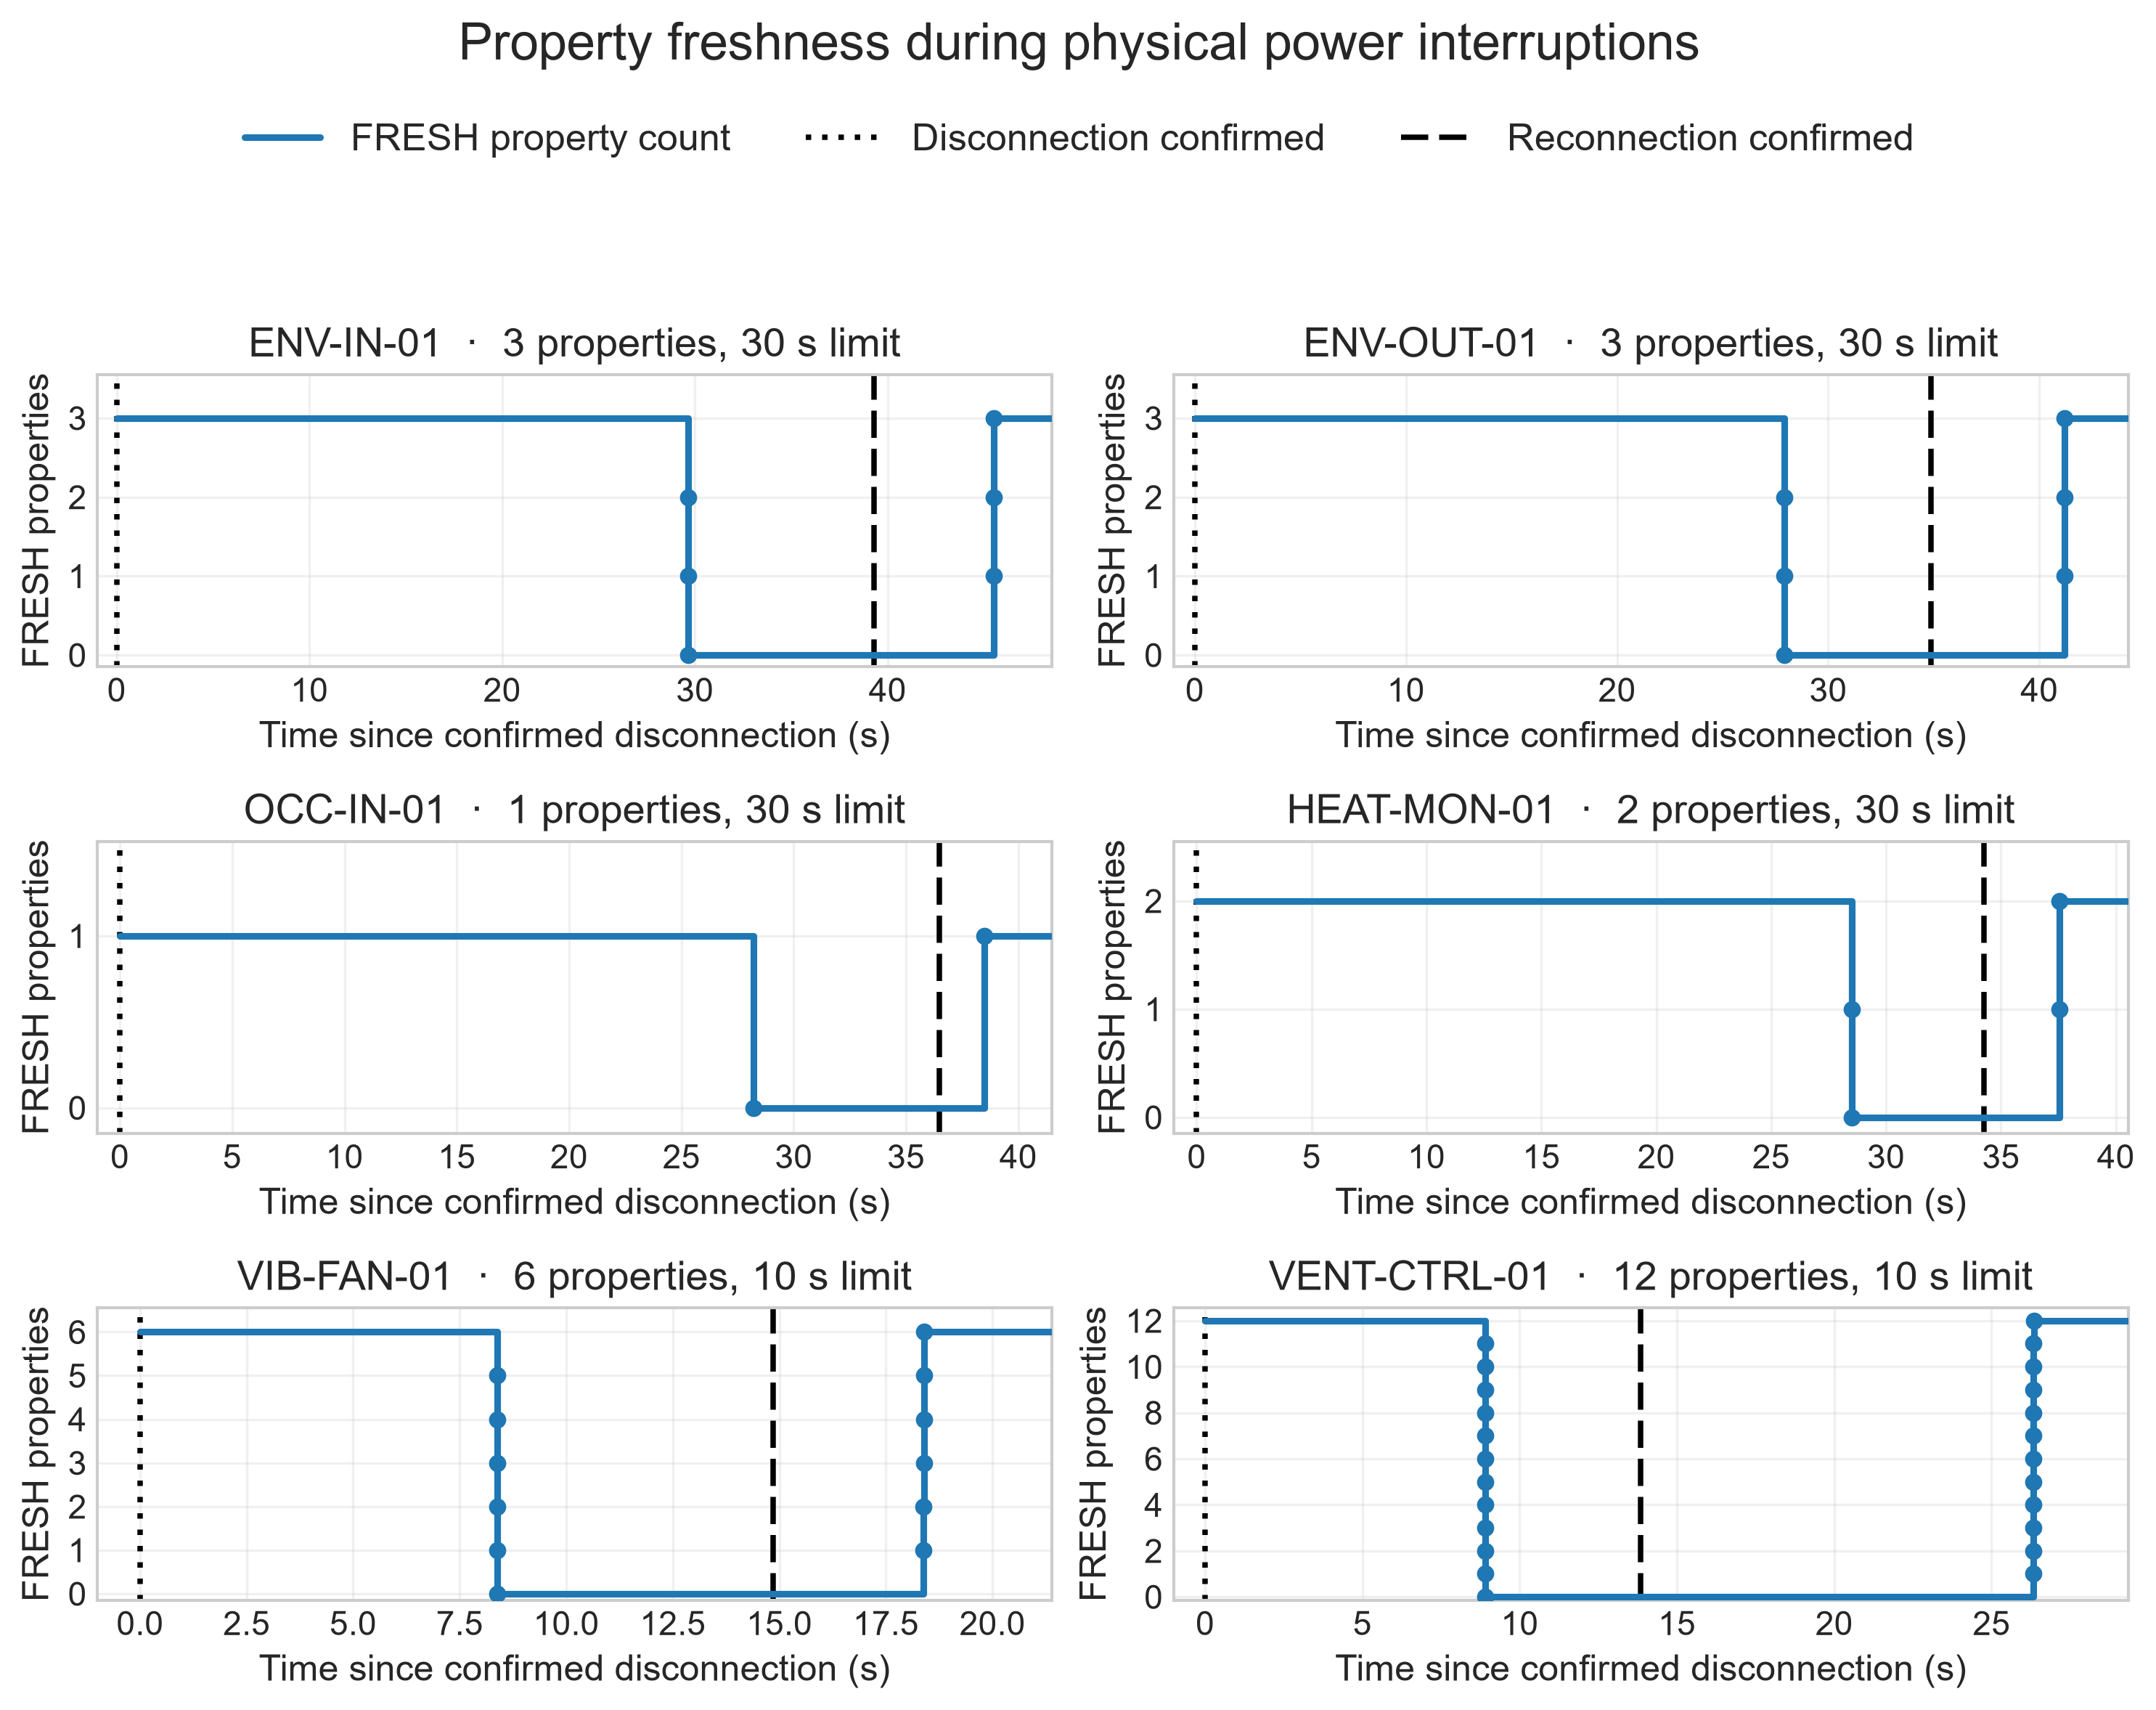

### Measurements during six power interruptions

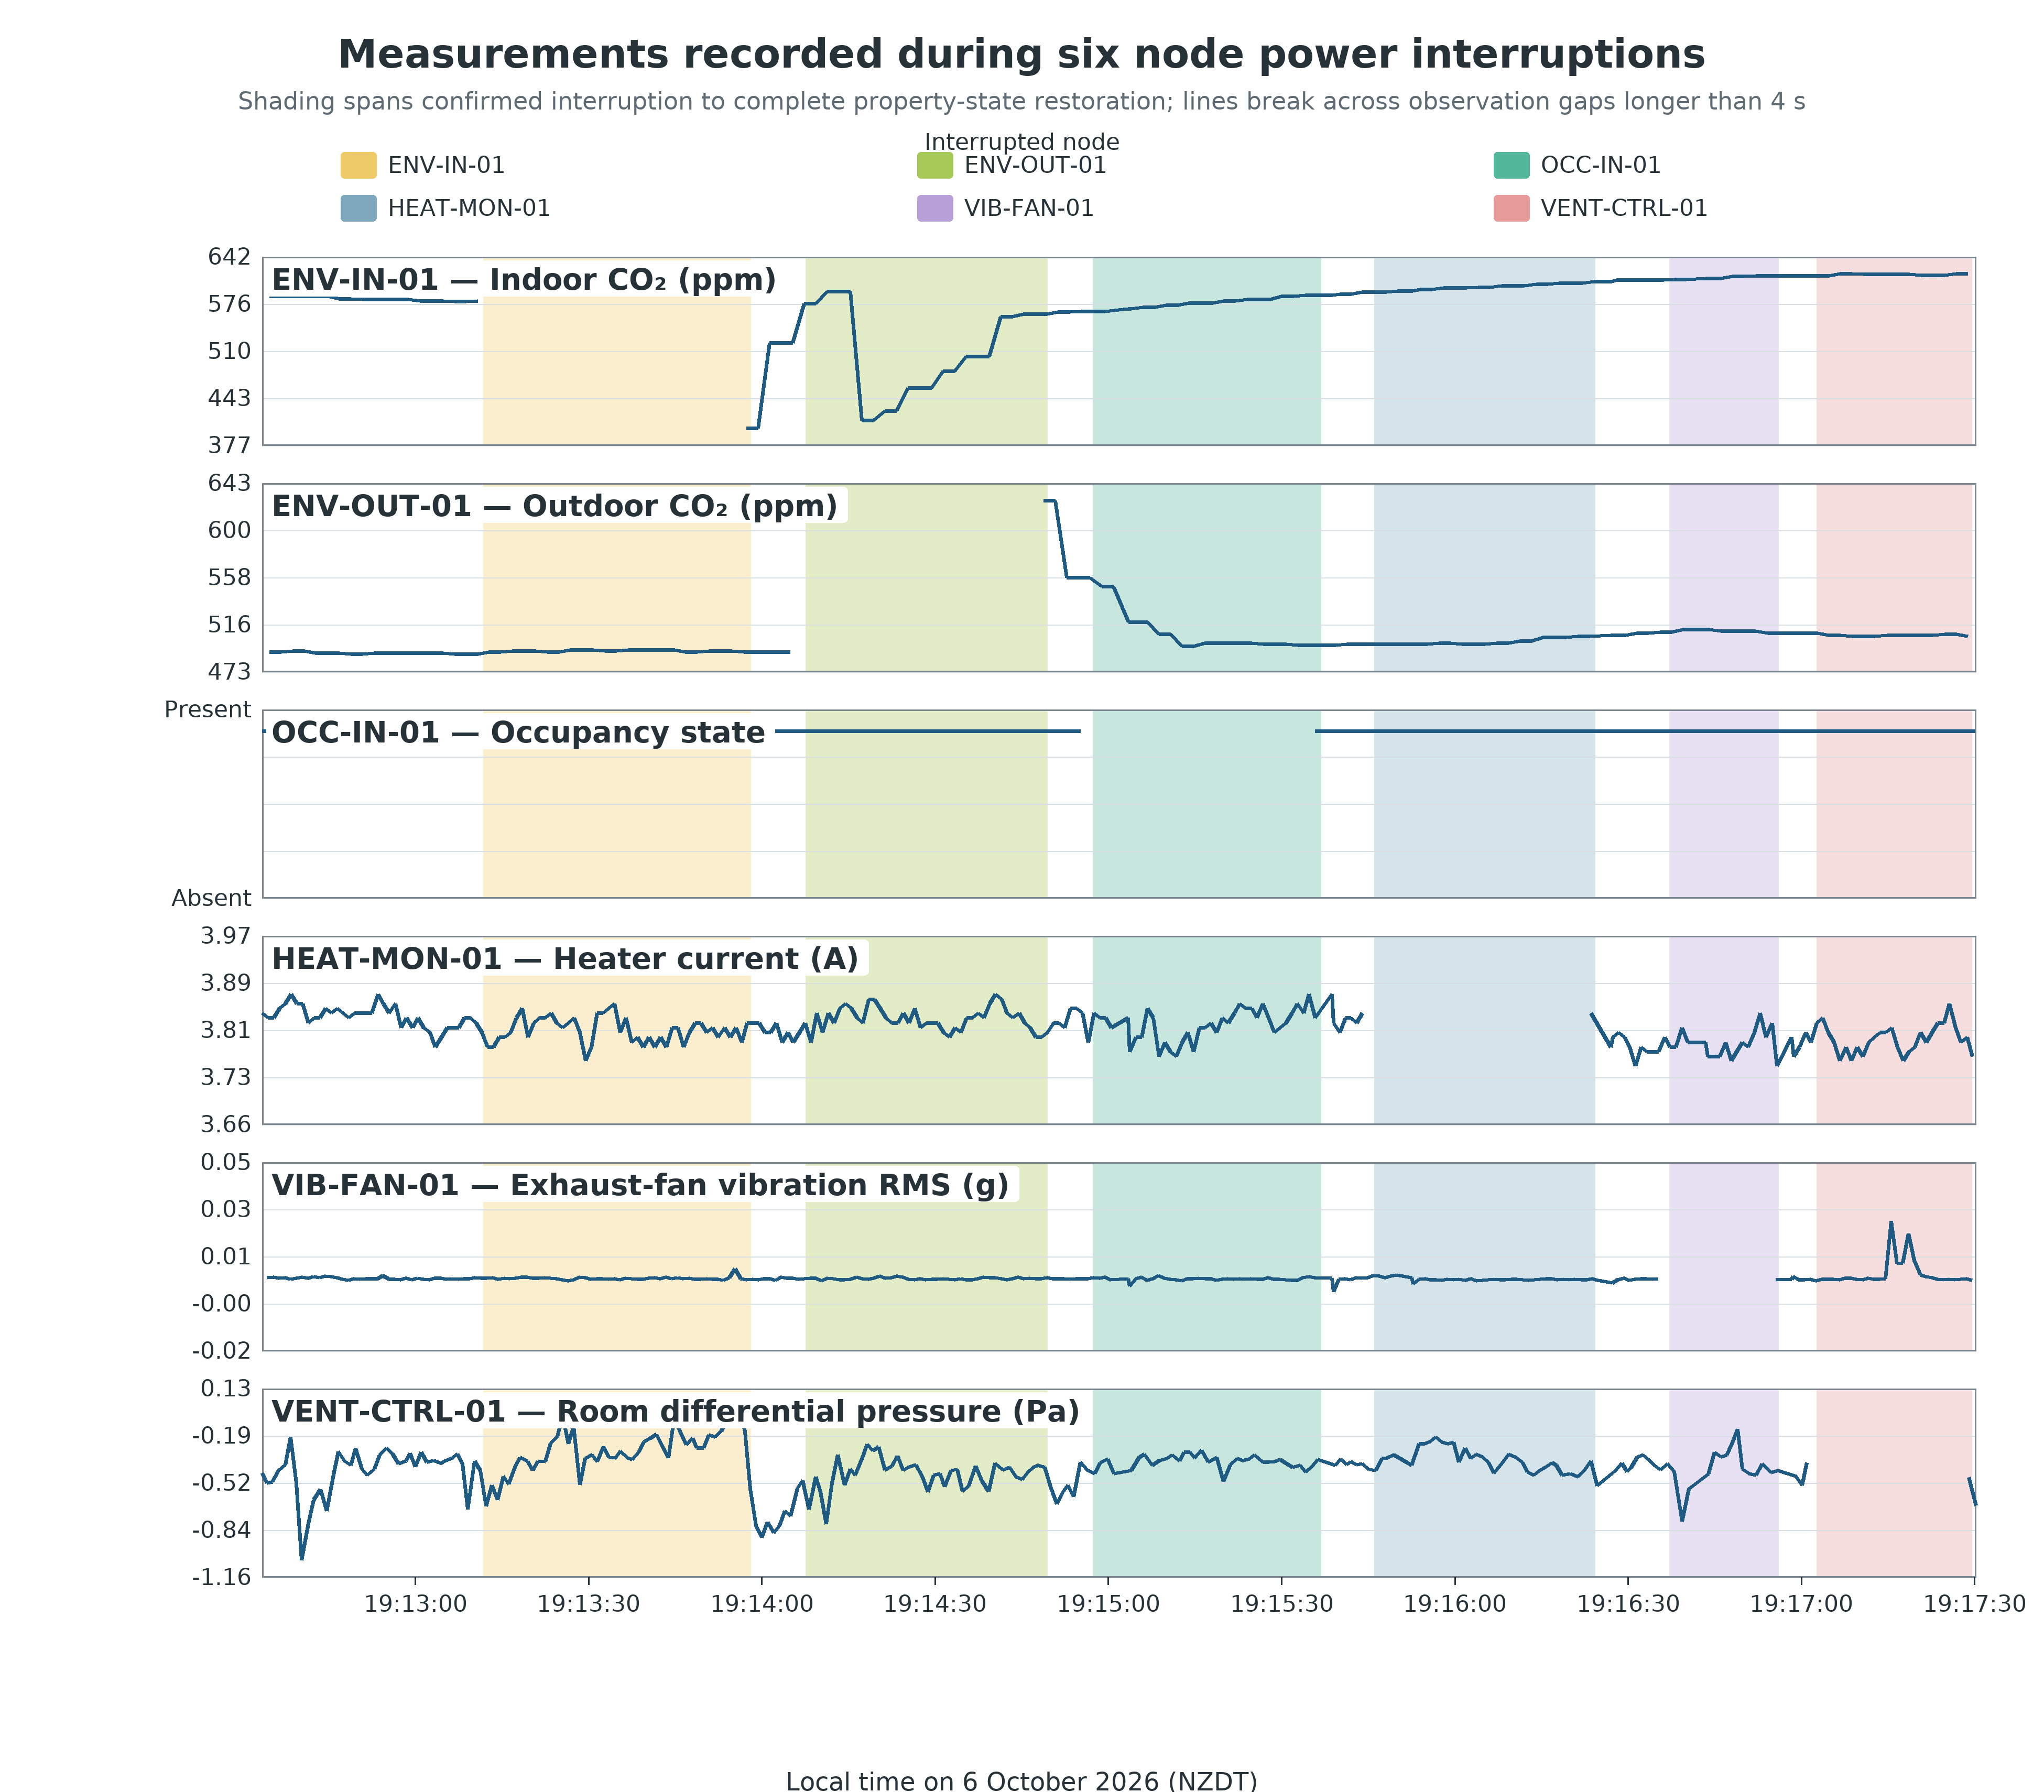

In [8]:
from indoortwin.evidence import display_plots
display_plots("01")
